# Tukey vs Hann: Which FFT Window Gives a Better Signal?

**Question:** `record2/post_process.py` `clean()` multiplies the whole 1.3 s capture by a Hann window before the FFT. Does recomputing the FFT with a short Tukey taper instead give the model a better signal, in both the gastronorm and the cardboard box?

| | Pipeline | Code |
|---|---|---|
| **hann** | the stored `vibration/04_ffts.npz`: band-pass 100-1000 Hz → × Hann over the whole capture → rfft | `record2/post_process.py` (what src6 and src7 `--window hann` train on) |
| **tukey** | the same, from `vibration/02_raw_shifts.npy`, but × Tukey (α = 0.02, 13 ms tapers at each end) | src7 `--window tukey` (`dataset.load_fft_raw`) |

Everything else (band-pass, bins, normalization) is identical; section 2 checks that recomputing the Hann pipeline from the raw shifts reproduces `04_ffts` exactly, so the window is the only difference.

| Section | Asks | Better = |
|---|---|---|
| 2 | why the window matters: where the chirp sits in the capture, and the gain the Hann puts on each frequency | |
| 3 | repeat noise: how different are two back-to-back captures of the same empty box? | lower |
| 4 | SNR(f): level of the object captures above repeat noise, per frequency | higher |
| 5 | move / noise: how much does moving the object change the spectrum, relative to repeat noise? | higher |
| 6 | probe: how well does a kernel ridge regression find the object's centre of mass from the model's input? | higher |

A gain that is the same for every capture cancels out of sections 3-5 (they are ratios, or differences of dB), so a window can only win there by keeping more signal relative to noise, not by tilting the spectrum.

Data: single-object captures of the 4 main objects (cube, candle, vase, soap dispenser) and the empty box, speakers 1/3/5/7 (gastro has no speaker 5), no rotated / lid / laser-shift / unseen-speaker / sideways layouts. Takes ~4 min (feature extraction ~1.5 min, probe ~2 min).

# 1 Setup

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "4"   # default = all cores, 100x slower on small matrices when the machine is busy
import json
import warnings
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, chirp, sosfiltfilt
from scipy.signal.windows import tukey
from scipy.spatial.distance import cdist
from sklearn.model_selection import GroupKFold

REPO = Path.cwd().parent
BOXES = dict(gastro="2026_09_27_gastronorm_four_objs", cardboard="2026_10_11_cardboard_four_objs")
OBJS = {"red-cube": "cube", "candle": "candle", "vase": "vase", "soap dispenser": "soap"}
SKIP = ("shift", "lid", "rotat", "speaker", "sideways")
REPS = ("hann", "tukey")
COLORS = dict(hann="#9a9893", tukey="#2a78d6")
BOX_COLORS = dict(gastro="#2a78d6", cardboard="#1baf7a")
warnings.filterwarnings("ignore")
summary = {}   # metric -> {(box, rep): "mean ± std"}, filled by every section, collected in the conclusion

FPS, NT = 2500, 3250                                                    # 2500 fps, 1.3 s capture
fr = np.fft.rfftfreq(NT, 1 / FPS); inband = (fr >= 100) & (fr <= 1000)  # 1170 bins, the same as 04_ffts
fb = fr[inband].reshape(117, 10).mean(1)                                # 117 bands of 10 bins (7.7 Hz), as in nb99
sos = butter(5, [100, 1000], fs=FPS, btype="band", output="sos")
HANN, TUKEY = np.hanning(NT), tukey(NT, 0.02)
REF = chirp(np.arange(FPS) / FPS, f0=100, t1=1.0, f1=1000, method="logarithmic")   # the played chirp at the camera rate

def band(ax, x, Y, c, label=None, **kw):   # plotting standard: line = mean over rows of Y, band = ±1 std
    m, s = np.mean(Y, 0), np.std(Y, 0)
    ax.fill_between(x, m - s, m + s, color=c, alpha=.15, lw=0)
    ax.plot(x, m, c=c, label=label, **kw)

def bars(ax, labels, M, S):                # grouped bars, one per rep: M = {rep: means}, S = {rep: stds}
    w = .8 / len(REPS)
    for k, rep in enumerate(REPS):
        x = np.arange(len(labels)) + (k - .5) * w
        ax.bar(x, M[rep], w * .92, color=COLORS[rep], label=rep)
        ax.errorbar(x, M[rep], yerr=S[rep], fmt="none", ecolor="#52514e", lw=1, capsize=3)
        for xi, m, s in zip(x, M[rep], S[rep]): ax.annotate(f"{m:.3g}", (xi, m + s), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(len(labels)), labels)
    ax.legend()

def pm(v, f=".3f"):                        # table standard: mean ± std
    v = np.asarray(v, float)
    return f"{np.nanmean(v):{f}} ± {np.nanstd(v):{f}}"

def show(*keys): return pd.DataFrame(summary).T.loc[list(keys)]

# 2 Why the Window Matters

## 2.1 The Two Pipelines, and a Check That Only the Window Differs

```
s(l,t,c)        = PCLK shift of laser l (10×10 grid), frame t, axis c ∈ {x, y}         # 02_raw_shifts.npy, (100, 3250, 2)
X_w(l,f,c)      = rfft_t( bandpass_100–1000Hz(s) · w(t) ),  keep 100 ≤ f ≤ 1000 Hz      # w = Hann (stored 04_ffts) or Tukey α=0.02
```

The cell below recomputes the Hann pipeline from the raw shifts for 20 random captures per box and compares it to the stored `04_ffts.npz`.

In [2]:
def meta(p): return {k: v for l in p.read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}
def fft(x): return np.fft.rfft(x, axis=1)[:, inband]                     # (L, 1170, 2)

rng = np.random.default_rng(0)
err = {}
for box, e in BOXES.items():
    dirs = sorted((REPO / "experiments" / e / "samples").iterdir())
    err[box] = max(np.abs(fft(sosfiltfilt(sos, np.load(d / "vibration/02_raw_shifts.npy"), axis=1) * HANN[None, :, None]) - (A := np.load(d / "vibration/04_ffts.npz")["fft"][0])).max() / np.abs(A).max()
                   for d in rng.choice(dirs, 20, replace=False))
pd.Series(err, name="max |recomputed hann − 04_ffts| / max |04_ffts|").to_frame()

,max |recomputed hann − 04_ffts| / max |04_ffts|
gastro,4.818522e-08
cardboard,5.039897e-08


## 2.2 Load the Captures

Per capture, from the raw shifts:
- `onset`: where the chirp starts in the capture, by matched filter: the lag that maximizes the cross-correlation of the band-passed shifts with the played chirp, summed over lasers and axes.
- `gain(f)`: the gain the Hann puts on each band, measured: `mean_{l,c} |X_hann| / mean_{l,c} |X_none|` (no window at all).
- for each window, `x(l,j,c) = mean_{f ∈ band j} |X(l,f,c)|` (magnitude, what the model sees) and the same in dB (`20 log10 |X|`, averaged over the band, as in nb99), 117 bands of 7.7 Hz.

In [3]:
def capture(d):
    x = sosfiltfilt(sos, np.load(d / "vibration/02_raw_shifts.npy"), axis=1)   # (100, 3250, 2)
    xc = np.fft.irfft(np.fft.rfft(x, 2 * NT, axis=1) * np.conj(np.fft.rfft(REF, 2 * NT))[None, :, None], 2 * NT, axis=1)[:, :NT]
    A = dict(hann=np.abs(np.load(d / "vibration/04_ffts.npz")["fft"][0]), tukey=np.abs(fft(x * TUKEY[None, :, None])))
    gain = A["hann"].mean((0, 2)) / np.abs(fft(x)).mean((0, 2))
    return ((xc ** 2).sum((0, 2)).argmax() / FPS, gain.reshape(117, 10).mean(1),
            {k: (a.reshape(100, 117, 10, 2).mean(2).astype(np.float32), (20 * np.log10(a + 1e-12)).reshape(100, 117, 10, 2).mean(2).astype(np.float32)) for k, a in A.items()})

rows = []
for box, e in BOXES.items():
    for p in sorted((REPO / "experiments" / e / "samples").glob("*/metadata.jsonl")):
        m = meta(p)
        obj = OBJS.get(next(iter(m["objects"]))) if m.get("n_objects") == 1 else ("empty" if m.get("is_empty_box") else None)
        if obj is None or m["speaker"] not in (1, 3, 5, 7) or any(k in m["layout"] for k in SKIP): continue
        com = m["avg_com"] if obj != "empty" else [np.nan, np.nan]
        rows.append(dict(box=box, obj=obj, layout=m["layout"], pos=m["position_id"], spk=m["speaker"],
                         row=com[0], col=com[1], size=np.sqrt(m["crop_overhead_shape"][0] * m["crop_overhead_shape"][1]), dir=p.parent))
df = pd.DataFrame(rows)
with ProcessPoolExecutor(24) as ex: res = list(ex.map(capture, df.dir, chunksize=8))
df["onset"] = [r[0] for r in res]
gain = np.stack([r[1] for r in res])                                                 # (captures, 117)
mag = {k: np.stack([r[2][k][0] for r in res]) for k in REPS}                         # (captures, 100, 117, 2)
db = {k: np.stack([r[2][k][1] for r in res]).reshape(len(df), -1) for k in REPS}     # (captures, 23 400)
del res
df.groupby(["box", "obj"]).agg(captures=("pos", "size"), positions=("pos", "nunique"), speakers=("spk", "nunique")).unstack(0)

captures        positions         speakers       
box    cardboard gastro cardboard gastro cardboard gastro
obj                                                      
candle      1156    780       289    260         4      3
cube        1116    843       279    281         4      3
empty         76     36        19     12         4      3
soap        1088    735       272    245         4      3
vase        1028    804       257    268         4      3

## 2.3 Where the Chirp Sits, and the Gain the Hann Puts on It

A log sweep maps frequency to time: the chirp is at frequency `f` at time `t(f) = onset + log10(f / 100)` s. The Hann is `w(t) = 0.5 − 0.5 cos(2π t / 1.3 s)`, so the signal at `f` is scaled by about `w(t(f))`. The noise is spread over the whole capture and gets the window's average (rms ≈ 0.61) at every frequency, so where `w(t(f))` < 0.61 the Hann costs SNR.

Left: the two windows over the capture, and the chirp's frequency (right axis) at the median onset. Right: the predicted gain `w(t(f))` and the measured `gain(f)` (mean ± std over captures) per box.

median              std            count        
box cardboard gastro cardboard gastro cardboard  gastro
spk                                                    
1       0.174  0.200     0.006  0.007    1116.0  1066.0
3       0.175  0.188     0.011  0.011    1116.0  1066.0
5       0.170    NaN     0.007    NaN    1116.0     NaN
7       0.170  0.178     0.005  0.008    1116.0  1066.0

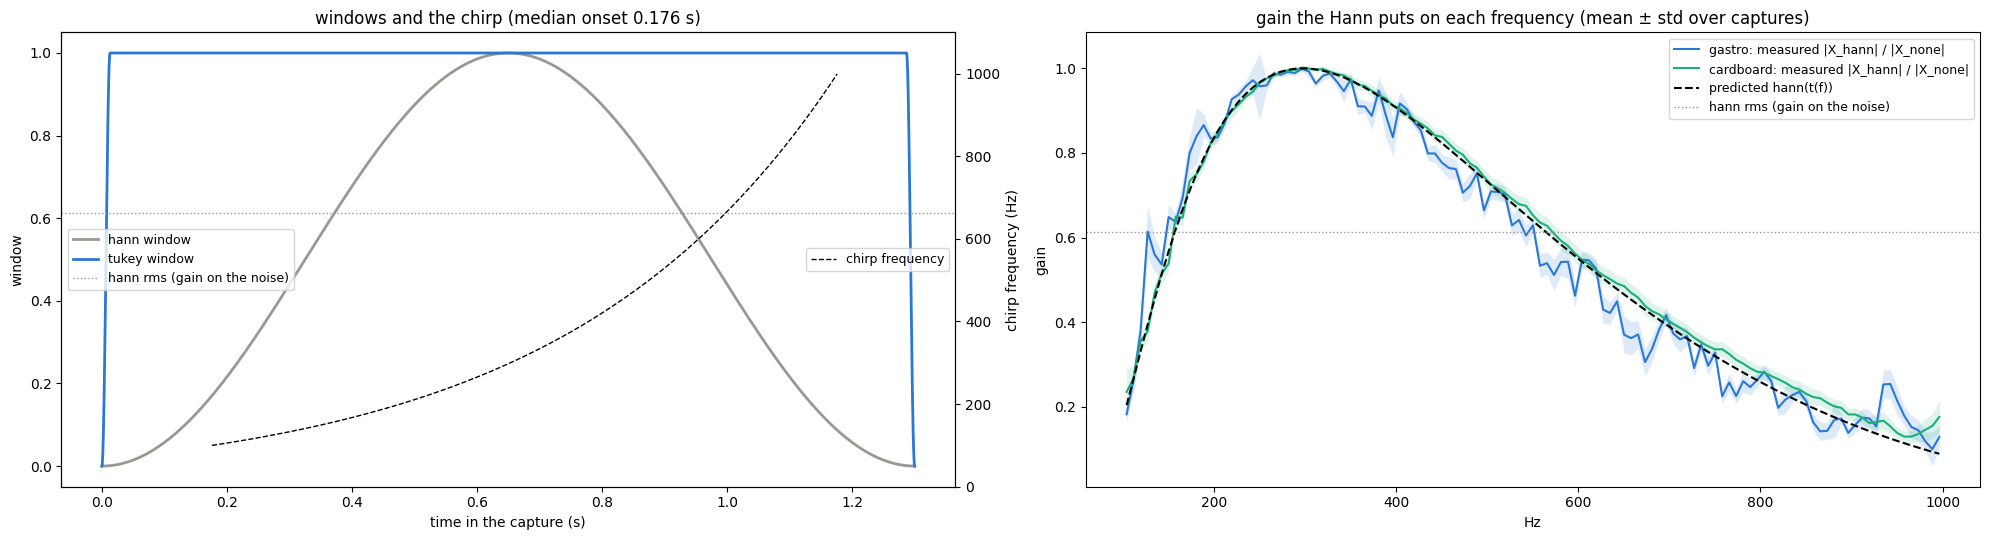

In [4]:
t = np.arange(NT) / FPS
fig, axs = plt.subplots(1, 2, figsize=(20, 5.5))
for rep, w in (("hann", HANN), ("tukey", TUKEY)): axs[0].plot(t, w, c=COLORS[rep], lw=2, label=f"{rep} window")
axs[0].axhline(np.sqrt((HANN ** 2).mean()), c=COLORS["hann"], ls=":", lw=1, label="hann rms (gain on the noise)")
ax2 = axs[0].twinx()
t0 = df.onset.median()
tc = t0 + np.arange(FPS) / FPS
ax2.plot(tc, 100 * 10 ** (tc - t0), c="k", lw=1, ls="--", label="chirp frequency")
ax2.set(ylabel="chirp frequency (Hz)", ylim=(0, 1100))
axs[0].set(xlabel="time in the capture (s)", ylabel="window", title=f"windows and the chirp (median onset {t0:.3f} s)")
axs[0].legend(loc="center left", fontsize=9); ax2.legend(loc="center right", fontsize=9)
for box in BOXES:
    band(axs[1], fb, gain[df.box == box], BOX_COLORS[box], f"{box}: measured |X_hann| / |X_none|")
axs[1].plot(fb, 0.5 - 0.5 * np.cos(2 * np.pi * (t0 + np.log10(fb / 100)) / 1.3), c="k", ls="--", label="predicted hann(t(f))")
axs[1].axhline(np.sqrt((HANN ** 2).mean()), c=COLORS["hann"], ls=":", lw=1, label="hann rms (gain on the noise)")
axs[1].set(xlabel="Hz", ylabel="gain", title="gain the Hann puts on each frequency (mean ± std over captures)")
axs[1].legend(fontsize=9)
plt.tight_layout()
df.groupby(["box", "spk"]).onset.agg(["median", "std", "count"]).unstack(0).round(3)

**Reading:** - The chirp starts 0.17-0.20 s into the capture in both boxes (std ≤ 11 ms within a speaker; speakers differ by up to 22 ms, their sound cards' output latency). It ends ~1.18 s, ~0.1 s before the capture does.
- The measured gain follows the prediction `hann(t(f))` closely in both boxes: ~0.2 at 100 Hz, 1.0 at ~300 Hz (the middle of the capture), ~0.1-0.15 at 1000 Hz. Gastro's is jagged because its sharp resonances ring past `t(f)`.
- Below the dotted line (the Hann's rms, its gain on the noise), the Hann scales the signal down more than the noise: **below ~150 Hz and above ~580 Hz**. That is where section 4 should show Tukey's SNR gain. Tukey is 1 over the whole chirp.
- Section 2.1: recomputing the Hann pipeline from the raw shifts matches `04_ffts` to 5e-8, so the window is the only difference between the two pipelines.

# 3 Repeat Noise

**Definitions.** `a`, `b` are two empty-box captures with the same speaker and layout, taken back to back. Nothing moved, so any difference is noise. Same pairs for both windows.

```
D_spec(a, b) = sqrt( mean_{l,j,c} (x_a[l,j,c] − x_b[l,j,c])² ),  x in dB     # one number per pair; a fixed per-band gain cancels
N(f)         = 10 log10( ½ mean_{l,c} (|X_a(l,f,c)| − |X_b(l,f,c)|)² )        # noise power per band, dB of |FFT|
```

`paired win` = fraction of pairs whose `D_spec` is lower with Tukey than with Hann.

gastro                     cardboard  \
                                           hann          tukey           hann   
noise D_spec (dB) ↓               1.448 ± 0.373  1.235 ± 0.348  1.565 ± 0.613   
noise: paired win (tukey < hann)            NaN      97% of 36            NaN   

                                                 
                                          tukey  
noise D_spec (dB) ↓               1.468 ± 0.670  
noise: paired win (tukey < hann)      60% of 84

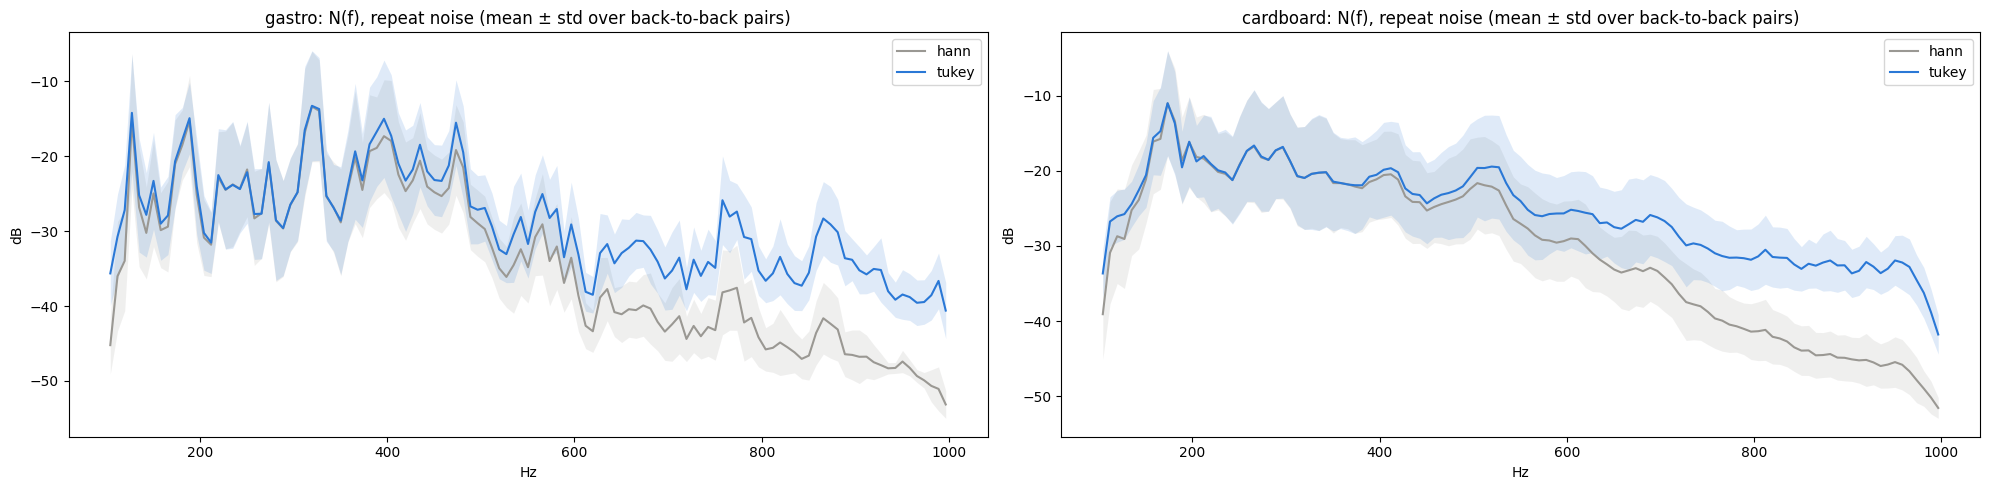

In [5]:
pairs = {box: [(i, j) for _, g in df[(df.box == box) & (df.obj == "empty")].groupby(["spk", "layout"]) for n, i in enumerate(g.index) for j in g.index[n + 1:]] for box in BOXES}
def dist(rep, a, b): return cdist(db[rep][a], db[rep][b]) / np.sqrt(db[rep].shape[1])
noise = {(box, rep): np.array([dist(rep, [i], [j])[0, 0] for i, j in pairs[box]]) for box in BOXES for rep in REPS}
N = {(box, rep): np.stack([10 * np.log10(((mag[rep][i] - mag[rep][j]) ** 2).mean((0, 2)) / 2) for i, j in pairs[box]]) for box in BOXES for rep in REPS}

fig, axs = plt.subplots(1, 2, figsize=(20, 5))
for ax, box in zip(axs, BOXES):
    for rep in REPS: band(ax, fb, N[box, rep], COLORS[rep], rep)
    ax.set(xlabel="Hz", ylabel="dB", title=f"{box}: N(f), repeat noise (mean ± std over back-to-back pairs)")
    ax.legend()
plt.tight_layout()
summary["noise D_spec (dB) ↓"] = {(box, rep): pm(noise[box, rep]) for box in BOXES for rep in REPS}
summary["noise: paired win (tukey < hann)"] = {(box, "tukey"): f"{(noise[box, 'tukey'] < noise[box, 'hann']).mean():.0%} of {len(pairs[box])}" for box in BOXES}
show("noise D_spec (dB) ↓", "noise: paired win (tukey < hann)")

**Reading:** - In absolute dB (plots), Tukey's noise is *higher* above ~500 Hz. Expected: there the Hann scaled noise and signal down together (gain 0.1-0.5), Tukey does not. Absolute noise is not comparable across windows; `D_spec` (a dB difference, the gain cancels) and SNR (section 4) are.
- `D_spec` is lower with Tukey in both boxes: gastro 1.45 → 1.24 dB (97% of pairs), cardboard 1.57 → 1.47 dB (only 60% of pairs: cardboard's pair noise is wide, std 0.6, a few drifting pairs dominate).

# 4 SNR per Frequency

```
L(f)   = 10 log10( mean_{captures, l, c} |X(l,f,c)|² )   # level of the object captures, dB of |FFT|
SNR(f) = L(f) − mean_pairs N(f)                          # dB; a fixed per-band gain cancels
```

Section 2 predicts Tukey wins most at the band edges (100-150 Hz and 700-1000 Hz), where the Hann scales the signal far below its rms. Std in the table is over the bands in each range.

gastro               cardboard            
                              hann       tukey        hann       tukey
SNR 100-150 Hz (dB) ↑   28.1 ± 2.9  31.3 ± 2.1  31.3 ± 1.4  37.3 ± 0.8
SNR 150-300 Hz (dB) ↑   32.3 ± 2.5  33.0 ± 2.8  33.5 ± 2.1  34.8 ± 3.1
SNR 300-700 Hz (dB) ↑   26.8 ± 1.9  27.5 ± 2.1  26.5 ± 1.7  27.1 ± 1.8
SNR 700-1000 Hz (dB) ↑  21.9 ± 3.3  25.8 ± 2.5  22.6 ± 1.5  25.0 ± 0.7
SNR all (dB) ↑          26.2 ± 4.4  28.1 ± 3.5  26.6 ± 4.2  28.3 ± 4.4

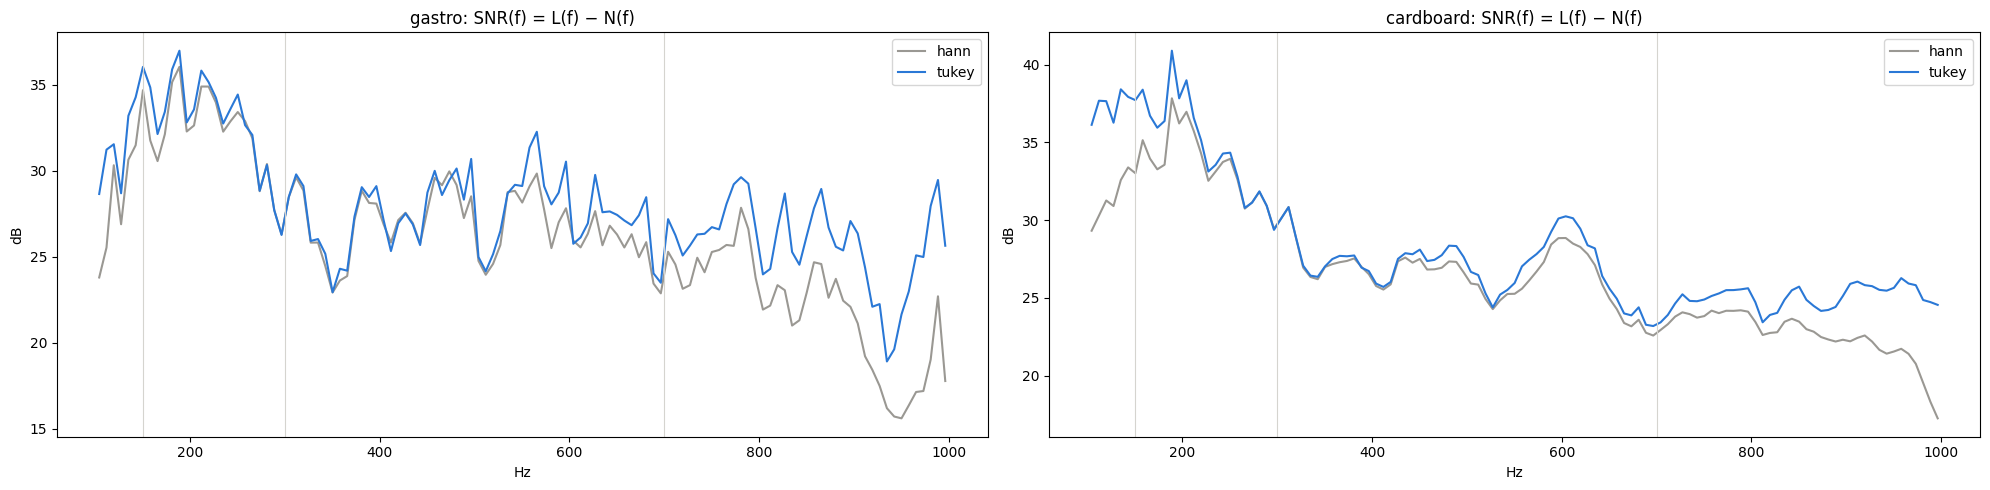

In [6]:
RANGES = [(100, 150), (150, 300), (300, 700), (700, 1000)]
snr = {}
for box in BOXES:
    o = (df.box == box).to_numpy() & (df.obj != "empty").to_numpy()
    for rep in REPS: snr[box, rep] = 10 * np.log10((mag[rep][o] ** 2).mean((0, 1, 3))) - N[box, rep].mean(0)
fig, axs = plt.subplots(1, 2, figsize=(20, 5))
for ax, box in zip(axs, BOXES):
    for rep in REPS: ax.plot(fb, snr[box, rep], c=COLORS[rep], label=rep)
    for lo, hi in RANGES[1:]: ax.axvline(lo, c="#d5d4cf", lw=.8)
    ax.set(xlabel="Hz", ylabel="dB", title=f"{box}: SNR(f) = L(f) − N(f)")
    ax.legend()
plt.tight_layout()
for lo, hi in RANGES: summary[f"SNR {lo}-{hi} Hz (dB) ↑"] = {(box, rep): pm(snr[box, rep][(fb >= lo) & (fb < hi)], ".1f") for box in BOXES for rep in REPS}
summary["SNR all (dB) ↑"] = {(box, rep): pm(snr[box, rep], ".1f") for box in BOXES for rep in REPS}
show(*[f"SNR {lo}-{hi} Hz (dB) ↑" for lo, hi in RANGES], "SNR all (dB) ↑")

**Reading:** - Tukey's SNR is higher in every range in both boxes, by the most where section 2.3 predicts: **gastro +3.2 dB at 100-150 Hz and +3.9 dB at 700-1000 Hz, cardboard +6.0 and +2.4 dB.**
- In the middle (300-700 Hz), where the Hann's gain is ~1, the gain is small (+0.6-0.7 dB): the Hann did little harm there, and Tukey adds back the ringing after the sweep and the start of the capture.
- The plots show it bin by bin: the curves overlap between ~250 and 500 Hz and separate at both ends.

# 5 Position Signal: move / noise

The same measure as nb99 section 4, per object. `a`, `b` are two captures of the same object with the same speaker; `com` is the object's centre of mass in the overhead crop (`H × W` px).

```
D_pos(a, b) = ‖com_a − com_b‖ / sqrt(H · W)                                   # how far the object moved, as a fraction of the box size
move        = median D_spec(D_pos > 0.25) − median D_spec(0 < D_pos < 0.05)   # far pairs minus close pairs: the position signal, dB
move/noise  = move / mean D_spec of that speaker's empty pairs                 # position signal in units of repeat noise
```

Bars are mean ± std over speakers.

gastro                     cardboard  \
                              hann          tukey           hann   
move/noise candle ↑  0.693 ± 0.162  0.919 ± 0.233  0.617 ± 0.162   
move/noise cube ↑    0.328 ± 0.048  0.504 ± 0.080  0.330 ± 0.078   
move/noise soap ↑    0.555 ± 0.137  0.792 ± 0.227  0.409 ± 0.144   
move/noise vase ↑    0.968 ± 0.113  1.270 ± 0.188  0.702 ± 0.205   

                                    
                             tukey  
move/noise candle ↑  0.772 ± 0.186  
move/noise cube ↑    0.439 ± 0.086  
move/noise soap ↑    0.538 ± 0.159  
move/noise vase ↑    0.880 ± 0.225

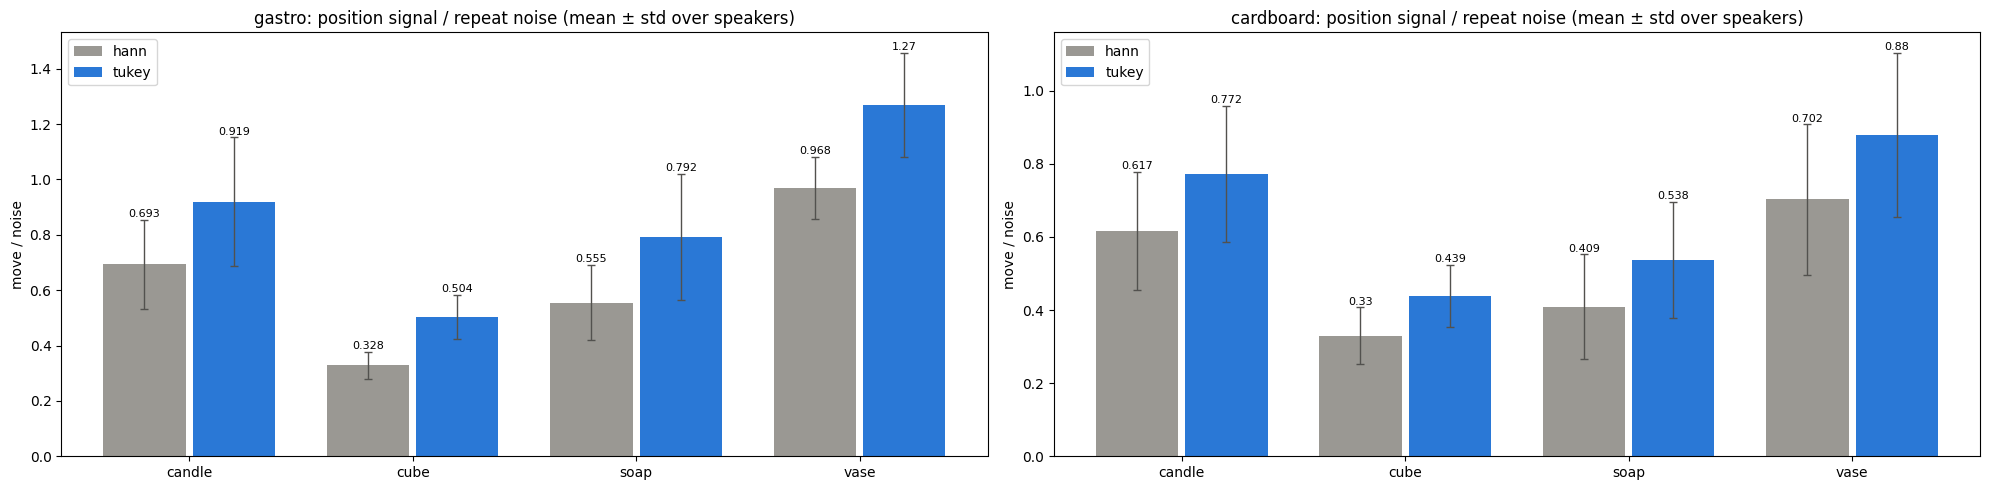

In [7]:
rows = []
for (box, obj, spk), c in df[df.obj != "empty"].groupby(["box", "obj", "spk"]):
    P = cdist(*[c[["row", "col"]].to_numpy(float)] * 2) / c["size"].iloc[0]
    for rep in REPS:
        D = dist(rep, c.index, c.index)
        nz = noise[box, rep][[k for k, (i, j) in enumerate(pairs[box]) if df.spk[i] == spk]].mean()
        rows.append(dict(box=box, obj=obj, spk=spk, rep=rep, move_noise=(np.median(D[P > .25]) - np.median(D[(P > 0) & (P < .05)])) / nz))
mn = pd.DataFrame(rows)
objs = sorted(set(df.obj) - {"empty"})
fig, axs = plt.subplots(1, 2, figsize=(20, 5))
for ax, box in zip(axs, BOXES):
    g = mn[mn.box == box].groupby(["rep", "obj"]).move_noise
    bars(ax, objs, {r: g.mean()[r][objs].to_numpy() for r in REPS}, {r: g.std(ddof=0)[r][objs].to_numpy() for r in REPS})
    ax.set(ylabel="move / noise", title=f"{box}: position signal / repeat noise (mean ± std over speakers)")
plt.tight_layout()
for obj in objs: summary[f"move/noise {obj} ↑"] = {(box, rep): pm(mn[(mn.box == box) & (mn.rep == rep) & (mn.obj == obj)].move_noise) for box in BOXES for rep in REPS}
show(*[f"move/noise {o} ↑" for o in objs])

**Reading:** - The position signal rises for every object in both boxes: **gastro +31 to +54%** (cube 0.33 → 0.50, soap 0.56 → 0.79), **cardboard +25 to +33%** (cube 0.33 → 0.44, vase 0.70 → 0.88). For the cube, the hann and tukey ranges (± 1 std over speakers) don't overlap in gastro.
- So the SNR gained at the band edges carries position information, not only level.

# 6 Probe: Decode the Object's Position From the Model's Input

The input the model actually trains on: per-capture `x / std(x)` of the band magnitude (src7 default `--signal magnitude --norm std`, here at 117 bands instead of 1170 bins). A kernel ridge regression (RBF, γ = 1 / median squared distance) predicts the centre of mass as a fraction of the box size, 5-fold `GroupKFold` over positions (no position in both train and test). The ridge strength is picked from {1e-3, 1e-2, 1e-1, 1} by mean skill, separately per window, so neither window gets a tuning advantage.

```
skill = 1 − mean ‖com_pred − com‖ / mean ‖mean(com_train) − com‖     # 0 = guessing the mean position, 1 = perfect
```

This probe ranked input representations in the same order as trained IoU (`scripts/signal_quality.py`). Bars are mean ± std over the 5 folds.

gastro                     cardboard  \
                                          hann          tukey           hann   
probe candle ↑                   0.863 ± 0.013  0.870 ± 0.011  0.857 ± 0.004   
probe cube ↑                     0.761 ± 0.027  0.787 ± 0.022  0.764 ± 0.012   
probe soap ↑                     0.858 ± 0.009  0.867 ± 0.004  0.821 ± 0.011   
probe vase ↑                     0.881 ± 0.014  0.888 ± 0.016  0.864 ± 0.012   
probe: folds where tukey > hann            NaN      95% of 20            NaN   

                                                
                                         tukey  
probe candle ↑                   0.879 ± 0.004  
probe cube ↑                     0.794 ± 0.011  
probe soap ↑                     0.843 ± 0.009  
probe vase ↑                     0.883 ± 0.010  
probe: folds where tukey > hann     100% of 20

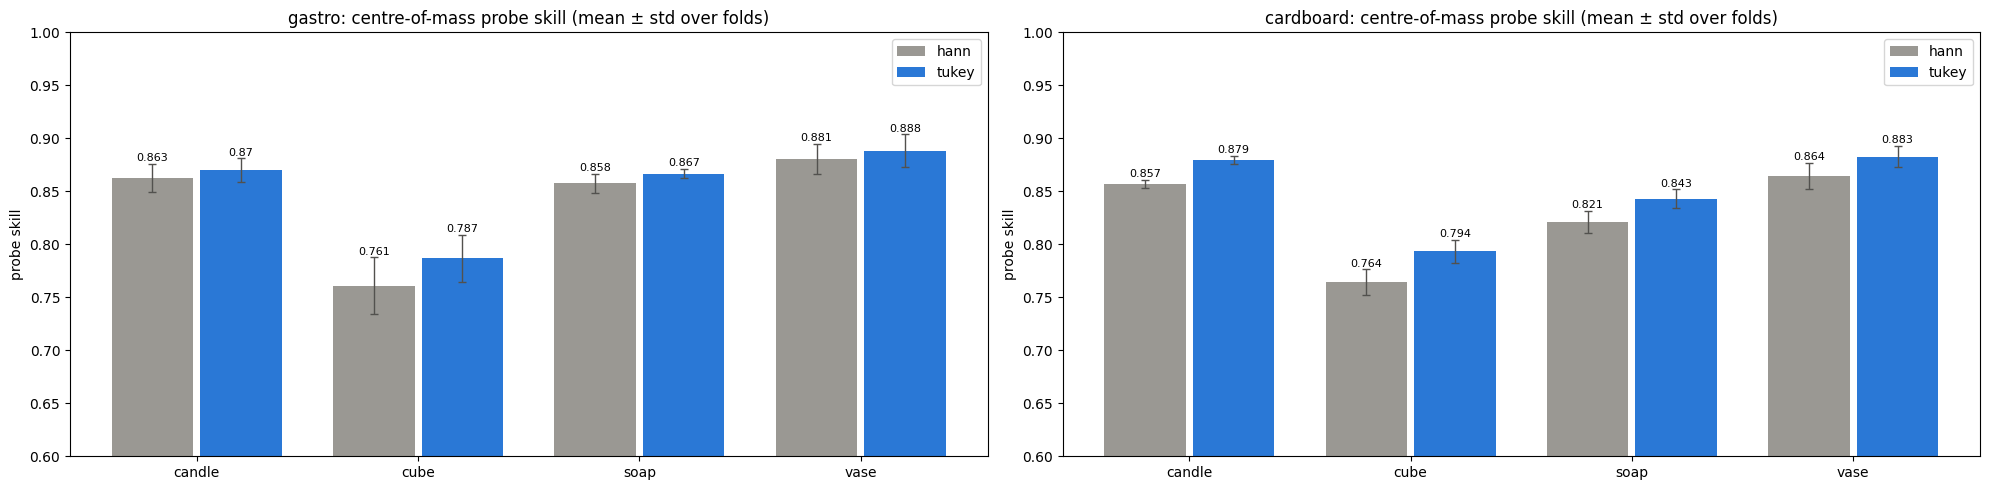

In [8]:
def probe(X, Y, groups, alphas=(1e-3, 1e-2, 1e-1, 1.0)):
    D = cdist(X, X, "sqeuclidean"); K = np.exp(-D / np.median(D))
    skill = {a: [] for a in alphas}
    for tr, te in GroupKFold(5).split(X, Y, groups):
        mu = Y[tr].mean(0); chance = np.linalg.norm(Y[te] - mu, axis=1).mean()
        for a in alphas:
            P = K[np.ix_(te, tr)] @ np.linalg.solve(K[np.ix_(tr, tr)] + a * np.eye(len(tr)), Y[tr] - mu) + mu
            skill[a].append(1 - np.linalg.norm(Y[te] - P, axis=1).mean() / chance)
    return max(skill.values(), key=np.mean)        # the 5 fold skills at the best alpha

rows = []
for (box, obj), c in df[df.obj != "empty"].groupby(["box", "obj"]):
    Y = c[["row", "col"]].to_numpy(float) / c["size"].to_numpy()[:, None]
    for rep in REPS:
        X = mag[rep][c.index].reshape(len(c), -1); X = X / X.std(1, keepdims=True)
        rows += [dict(box=box, obj=obj, rep=rep, fold=k, skill=s) for k, s in enumerate(probe(X, Y, c.pos.to_numpy()))]
pr = pd.DataFrame(rows)
fig, axs = plt.subplots(1, 2, figsize=(20, 5))
for ax, box in zip(axs, BOXES):
    g = pr[pr.box == box].groupby(["rep", "obj"]).skill
    bars(ax, objs, {r: g.mean()[r][objs].to_numpy() for r in REPS}, {r: g.std(ddof=0)[r][objs].to_numpy() for r in REPS})
    ax.set(ylabel="probe skill", ylim=(.6, 1), title=f"{box}: centre-of-mass probe skill (mean ± std over folds)")
plt.tight_layout()
for obj in objs: summary[f"probe {obj} ↑"] = {(box, rep): pm(pr[(pr.box == box) & (pr.rep == rep) & (pr.obj == obj)].skill) for box in BOXES for rep in REPS}
summary["probe: folds where tukey > hann"] = {(box, "tukey"): f"{(pv := pr[pr.box == box].pivot_table(index=['obj', 'fold'], columns='rep', values='skill')).pipe(lambda p: (p.tukey > p.hann).mean()):.0%} of {len(pv)}" for box in BOXES}
show(*[f"probe {o} ↑" for o in objs], "probe: folds where tukey > hann")

**Reading:** - The probe's skill is higher with Tukey for every object in both boxes, in 95% (gastro) and 100% (cardboard) of the object × fold pairs.
- The gains are small (+0.007 to +0.030): the per-sample std normalization and the kernel already tolerate a fixed spectral tilt. The **cube**, the hardest object, gains the most (+0.026 gastro, +0.030 cardboard).

# 7 Conclusion

In [9]:
pd.set_option("display.max_colwidth", 30)
out = pd.DataFrame(summary).T
out.columns = pd.MultiIndex.from_tuples(out.columns)
out[[(b, r) for b in BOXES for r in REPS]].fillna("")

gastro                     cardboard  \
                                         hann          tukey           hann   
noise D_spec (dB) ↓             1.448 ± 0.373  1.235 ± 0.348  1.565 ± 0.613   
noise: paired win (tukey < ...                     97% of 36                  
SNR 100-150 Hz (dB) ↑              28.1 ± 2.9     31.3 ± 2.1     31.3 ± 1.4   
SNR 150-300 Hz (dB) ↑              32.3 ± 2.5     33.0 ± 2.8     33.5 ± 2.1   
SNR 300-700 Hz (dB) ↑              26.8 ± 1.9     27.5 ± 2.1     26.5 ± 1.7   
SNR 700-1000 Hz (dB) ↑             21.9 ± 3.3     25.8 ± 2.5     22.6 ± 1.5   
SNR all (dB) ↑                     26.2 ± 4.4     28.1 ± 3.5     26.6 ± 4.2   
move/noise candle ↑             0.693 ± 0.162  0.919 ± 0.233  0.617 ± 0.162   
move/noise cube ↑               0.328 ± 0.048  0.504 ± 0.080  0.330 ± 0.078   
move/noise soap ↑               0.555 ± 0.137  0.792 ± 0.227  0.409 ± 0.144   
move/noise vase ↑               0.968 ± 0.113  1.270 ± 0.188  0.702 ± 0.205   
probe candle ↑                  0.863 ± 0.013  0.870 ± 0.011  0.857 ± 0.004   
probe cube ↑                    0.761 ± 0.027  0.787 ± 0.022  0.764 ± 0.012   
probe soap ↑                    0.858 ± 0.009  0.867 ± 0.004  0.821 ± 0.011   
probe vase ↑                    0.881 ± 0.014  0.888 ± 0.016  0.864 ± 0.012   
probe: folds where tukey > ...                     95% of 20                  

                                               
                                        tukey  
noise D_spec (dB) ↓             1.468 ± 0.670  
noise: paired win (tukey < ...      60% of 84  
SNR 100-150 Hz (dB) ↑              37.3 ± 0.8  
SNR 150-300 Hz (dB) ↑              34.8 ± 3.1  
SNR 300-700 Hz (dB) ↑              27.1 ± 1.8  
SNR 700-1000 Hz (dB) ↑             25.0 ± 0.7  
SNR all (dB) ↑                     28.3 ± 4.4  
move/noise candle ↑             0.772 ± 0.186  
move/noise cube ↑               0.439 ± 0.086  
move/noise soap ↑               0.538 ± 0.159  
move/noise vase ↑               0.880 ± 0.225  
probe candle ↑                  0.879 ± 0.004  
probe cube ↑                    0.794 ± 0.011  
probe soap ↑                    0.843 ± 0.009  
probe vase ↑                    0.883 ± 0.010  
probe: folds where tukey > ...     100% of 20

**Tukey is better than Hann on every metric, for every object, in both boxes.**

- **Why:** the chirp is a log sweep, so the Hann over the whole capture is a frequency-dependent gain on the signal (~0.2 at 100 Hz, 1 at 300 Hz, ~0.1 at 1000 Hz) but only its rms (0.61) on the noise, which is spread over the whole capture. Below ~150 Hz and above ~580 Hz it throws away signal faster than noise.
- **Effect:** SNR up to +3-6 dB at the band edges, lower repeat noise, the position signal (move / noise) up 25-54%, and a higher position probe for every object (95-100% of folds).
- **Caveats:** cardboard's repeat-noise win is only 60% of pairs; the probe is a proxy (117 bands, kernel ridge), not the model. The trained comparison is `scripts/window_src7.sh` (src7 `--window hann` vs `--window tukey`, gastronorm and cardboard, wandb group `fft-window`).
- **Use:** src7 `--window tukey` recomputes the FFT from `02_raw_shifts.npy`; the stored `04_ffts` and src6 are unchanged.